# Capítulo 3 · Actividad: limpieza de datos y outliers

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/riosinda/ml-course/blob/main/notebooks/exercises/chapter_03/02_actividad_limpieza_outliers.ipynb)

Vas a aplicar lo que viste en la notebook de clase `04_limpieza_y_outliers` a **tres datasets distintos**. Cada uno tiene problemas diferentes, igual que en la vida real.

### Antes de empezar

1. **Copia esta notebook a `workspace/`** y trabaja sobre la copia.
2. Si todavía no tienes los datos, descárgalos desde la raíz del repo:
   ```bash
   uv run python scripts/download_data.py
   ```

### Cómo trabajar

- Cada ejercicio tiene una celda `# Tu código aquí`. Añade todas las celdas que necesites.
- En las celdas ✍️ **justifica tus decisiones**: en limpieza de datos casi nunca hay una única respuesta correcta, pero siempre tiene que haber un motivo.
- Al terminar, ejecuta **Kernel → Restart & Run All**.

| Parte | Datos | Tema |
|---|---|---|
| A. Empleados | una tabla pequeña creada en la notebook | Limpieza estructural e imputación |
| B. Pingüinos | `data/penguins.csv` | Valores faltantes |
| C. Viviendas de California | `data/california_housing.csv` | Outliers |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.impute import SimpleImputer

# Carpeta data/ en la raíz del repo: subimos de carpeta en carpeta hasta dar con pyproject.toml
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = raiz / "data"

---
## Parte A · Empleados 👩‍💼

Recursos Humanos te pasa esta tabla, exportada a mano de varias hojas de cálculo. Ejecuta la celda para crearla.

In [2]:
empleados = pd.DataFrame({
    "nombre": ["Ana", "Luis", "Marta", "Luis", "Pedro", "Sofía", "Juan", "Elena",
               "Diego", "Carla", "Raúl", "Elena", "Iván", "Lucía"],
    "departamento": [" ventas", "IT", "it ", "IT", "Ventas", "RRHH", "rrhh", "VENTAS",
                     "It", "ventas ", "IT", "VENTAS", "RRHH", " Rrhh"],
    "edad": [34, np.nan, 29, np.nan, 45, 38, np.nan, 41, 27, np.nan, 52, 41, 31, 36],
    "salario": ["$35,000", "$52,000", "$48,500", "$52,000", "39000", "$41,200", "$37,800",
                "40500", "$47,000", "$36,900", "$61,000", "40500", "$39,900", "$42,300"],
    "fecha_ingreso": ["2019-03-15", "2020-07-01", "2021-01-10", "2020-07-01", "2015-09-30",
                      "2018-11-05", "2022-02-14", "2016-06-20", "2023-04-03", "2021-08-16",
                      "2012-01-09", "2016-06-20", "2019-10-21", "2017-05-02"],
})

empleados

,nombre,departamento,edad,salario,fecha_ingreso
0,Ana,ventas,34.0,"$35,000",2019-03-15
1,Luis,IT,NaN,"$52,000",2020-07-01
2,Marta,it,29.0,"$48,500",2021-01-10
3,Luis,IT,NaN,"$52,000",2020-07-01
4,Pedro,Ventas,45.0,39000,2015-09-30
5,Sofía,RRHH,38.0,"$41,200",2018-11-05
6,Juan,rrhh,NaN,"$37,800",2022-02-14
7,Elena,VENTAS,41.0,40500,2016-06-20
8,Diego,It,27.0,"$47,000",2023-04-03
9,Carla,ventas,NaN,"$36,900",2021-08-16


### Ejercicio 1 · Diagnóstico

Haz el diagnóstico de calidad de `empleados`: tipos de cada columna, valores faltantes, filas duplicadas y cómo están escritas las categorías.

In [3]:
print("Forma:", empleados.shape)
empleados.head()

Forma: (14, 5)


,nombre,departamento,edad,salario,fecha_ingreso
0,Ana,ventas,34.0,"$35,000",2019-03-15
1,Luis,IT,NaN,"$52,000",2020-07-01
2,Marta,it,29.0,"$48,500",2021-01-10
3,Luis,IT,NaN,"$52,000",2020-07-01
4,Pedro,Ventas,45.0,39000,2015-09-30


In [4]:
empleados.info()

<class 'pandas.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   nombre         14 non-null     str    
 1   departamento   14 non-null     str    
 2   edad           10 non-null     float64
 3   salario        14 non-null     str    
 4   fecha_ingreso  14 non-null     str    
dtypes: float64(1), str(4)
memory usage: 692.0 bytes


In [5]:
# Valores faltantes: cantidad y porcentaje por columna
pd.DataFrame({
    "nulos": empleados.isna().sum(),
    "porcentaje": (empleados.isna().mean() * 100).round(1),
})

,nulos,porcentaje
nombre,0,0.0
departamento,0,0.0
edad,4,28.6
salario,0,0.0
fecha_ingreso,0,0.0


In [6]:
# Filas con algún valor faltante (axis=1: ¿hay algún NaN en la fila?)
empleados[empleados.isna().any(axis=1)].head()

,nombre,departamento,edad,salario,fecha_ingreso
1,Luis,IT,NaN,"$52,000",2020-07-01
3,Luis,IT,NaN,"$52,000",2020-07-01
6,Juan,rrhh,NaN,"$37,800",2022-02-14
9,Carla,ventas,NaN,"$36,900",2021-08-16


In [7]:
print("Filas duplicadas:", empleados.duplicated().sum())

Filas duplicadas: 2


In [8]:
# Categorías: ¿están bien escritas?
for col in ["nombre", "departamento"]:
    print(empleados[col].value_counts(dropna=False), "\n")

nombre
Luis     2
Elena    2
Ana      1
Marta    1
Pedro    1
Sofía    1
Juan     1
Diego    1
Carla    1
Raúl     1
Iván     1
Lucía    1
Name: count, dtype: int64 

departamento
IT         3
RRHH       2
VENTAS     2
 ventas    1
it         1
Ventas     1
rrhh       1
It         1
ventas     1
 Rrhh      1
Name: count, dtype: int64 



In [9]:
# ¿Por qué el precio es texto? Veamos algunos valores
empleados.loc[empleados["salario"].str.startswith("$"), "salario"].head()

0    $35,000
1    $52,000
2    $48,500
3    $52,000
5    $41,200
Name: salario, dtype: str

In [10]:
empleados.describe()

,edad
count,10.000000
mean,37.400000
std,7.676805
min,27.000000
25%,31.750000
50%,37.000000
75%,41.000000
max,52.000000


✍️ **Pregunta:** haz una lista de todos los problemas que encontraste.

**📋 Resultado del diagnóstico**

| Problema | Dónde | Se arregla en |
|---|---|---|
| Filas duplicadas | 2 filas | Ejercicio 2 |
| Texto inconsistente | `departamento` ("IT", "it", "It") | Ejercicio 3 |
| Tipos incorrectos | `salario` (texto con `$` y comas), `fecha_ingreso` | Ejercicio 4 |
| Valores faltantes | `edad` | Ejercicio 5 |

### Ejercicio 2 · Duplicados

Elimina las filas duplicadas. ¿Cuántas filas quedan?

In [11]:
empleados = empleados.drop_duplicates()
print("Filas tras eliminar duplicados:", len(empleados))

Filas tras eliminar duplicados: 12


### Ejercicio 3 · Texto inconsistente

Normaliza `departamento` para que queden **exactamente tres** valores: `Ventas`, `IT` y `RRHH` (las siglas, en mayúsculas).

In [12]:
print("Antes:  ", empleados["departamento"].unique())
empleados["departamento"] = empleados["departamento"].str.strip().str.upper()
print("Después:", empleados["departamento"].unique())

Antes:   <StringArray>
[' ventas',      'IT',     'it ',  'Ventas',    'RRHH',    'rrhh',  'VENTAS',
      'It', 'ventas ',   ' Rrhh']
Length: 10, dtype: str
Después: <StringArray>
['VENTAS', 'IT', 'RRHH']
Length: 3, dtype: str


### Ejercicio 4 · Tipos de datos

a) Convierte `salario` a número. Ojo: no todos los valores tienen el mismo formato.

In [13]:
empleados["salario"] = (empleados["salario"]
                .str.replace("$", "", regex=False)
                .str.replace(",", "", regex=False))
empleados["salario"] = pd.to_numeric(empleados["salario"], errors="coerce")

empleados["salario"].head()

0    35000
1    52000
2    48500
4    39000
5    41200
Name: salario, dtype: int64

In [14]:
empleados["salario"].describe()

count       12.000000
mean     43425.000000
std       7464.598266
min      35000.000000
25%      38700.000000
50%      40850.000000
75%      47375.000000
max      61000.000000
Name: salario, dtype: float64

b) Convierte `fecha_ingreso` a fecha y crea la columna `año_ingreso`.

In [15]:
empleados["fecha_ingreso"] = pd.to_datetime(empleados["fecha_ingreso"])
empleados["fecha_ingreso"].head()

0   2019-03-15
1   2020-07-01
2   2021-01-10
4   2015-09-30
5   2018-11-05
Name: fecha_ingreso, dtype: datetime64[us]

In [16]:
empleados["año_ingreso"] = empleados["fecha_ingreso"].dt.year
empleados[["fecha_ingreso", "año_ingreso"]].head()

,fecha_ingreso,año_ingreso
0,2019-03-15,2019
1,2020-07-01,2020
2,2021-01-10,2021
4,2015-09-30,2015
5,2018-11-05,2018


c) Comprueba los tipos con `dtypes`.

In [17]:
empleados.dtypes

nombre                      str
departamento                str
edad                    float64
salario                   int64
fecha_ingreso    datetime64[us]
año_ingreso               int32
dtype: object

### Ejercicio 5 · Imputación

a) Crea una columna `edad_faltante` que indique qué empleados no tenían la edad.

b) Rellena la edad con la **mediana de su departamento**.

c) Comprueba que ya no quedan nulos y muestra la tabla final.

In [18]:
empleados["edad_faltante"] = empleados["edad"].isna()
empleados["edad"] = empleados["edad"].fillna(
    empleados.groupby("departamento")["edad"].transform("median")
)

print("Edades faltantes después de imputar:", empleados["edad"].isna().sum())
empleados[["nombre", "departamento", "edad", "edad_faltante"]]

Edades faltantes después de imputar: 0


,nombre,departamento,edad,edad_faltante
0,Ana,VENTAS,34.0,False
1,Luis,IT,29.0,True
2,Marta,IT,29.0,False
4,Pedro,VENTAS,45.0,False
5,Sofía,RRHH,38.0,False
6,Juan,RRHH,36.0,True
7,Elena,VENTAS,41.0,False
8,Diego,IT,27.0,False
9,Carla,VENTAS,41.0,True
10,Raúl,IT,52.0,False


✍️ **Pregunta:** ¿por qué la mediana del departamento y no la mediana de todos los empleados? ¿En qué caso daría igual?

La edad está relacionada con el departamento: las edades típicas pueden variar entre IT, RRHH y Ventas. Usar la mediana de cada departamento conserva mejor esas diferencias y evita que un departamento con edades distintas influya demasiado en la imputación. Daría igual usar la mediana global si todas las medianas departamentales fueran iguales (o si solo existiera un departamento).

---
## Parte B · Pingüinos 🐧 (valores faltantes)

El archivo `data/penguins.csv` tiene medidas de 344 pingüinos de tres especies. Columnas: `species`, `island`, `bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g` y `sex`.

### Ejercicio 6 · Diagnóstico de faltantes

a) Carga los datos en `pinguinos`.

b) Calcula cuántos valores faltan en cada columna y qué porcentaje representan.

c) Muestra las filas que tienen algún valor faltante.

In [19]:
pinguinos = pd.read_csv(DATA_DIR / "penguins.csv")

faltantes_pinguinos = pd.DataFrame({
    "nulos": pinguinos.isna().sum(),
    "porcentaje": (pinguinos.isna().mean() * 100).round(2),
})
print(faltantes_pinguinos)

filas_con_faltantes = pinguinos[pinguinos.isna().any(axis=1)]
print("Filas con algún valor faltante:", len(filas_con_faltantes))
filas_con_faltantes

                   nulos  porcentaje
species                0        0.00
island                 0        0.00
bill_length_mm         2        0.58
bill_depth_mm          2        0.58
flipper_length_mm      2        0.58
body_mass_g            2        0.58
sex                   11        3.20
Filas con algún valor faltante: 11


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN
246,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,NaN
286,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN
324,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN
336,Gentoo,Biscoe,44.5,15.7,217.0,4875.0,NaN


✍️ **Pregunta:** ¿ves algún patrón en las filas con faltantes? ¿Faltan los datos de forma parecida en todas?

Los faltantes no se distribuyen igual: las cuatro medidas numéricas faltan solo en dos filas y, en esas filas, faltan todas a la vez. En cambio, `sex` falta en 11 pingüinos que sí conservan las medidas. Por tanto, los faltantes numéricos parecen concentrarse en registros incompletos, mientras que el sexo tiene faltantes independientes.

### Ejercicio 7 · Eliminar o imputar

Hay pingüinos a los que les faltan **todas** las medidas. Elimínalos y comprueba cuántas filas quedan.

In [20]:
medidas = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
pinguinos_completos = pinguinos.dropna(subset=medidas).copy()
print("Filas antes:", len(pinguinos))
print("Filas después de eliminar pingüinos sin medidas:", len(pinguinos_completos))

Filas antes: 344
Filas después de eliminar pingüinos sin medidas: 342


✍️ **Pregunta:** ¿por qué en este caso es mejor eliminar esas filas que imputarlas?

Es mejor eliminarlas porque esas dos filas no contienen ninguna de las cuatro medidas numéricas. No hay información suficiente para calcular una imputación razonable; rellenarlas obligaría a inventar un pingüino completo y podría introducir datos artificiales. Solo se eliminan 2 de 344 filas, así que la pérdida de información es pequeña.

### Ejercicio 8 · Dos estrategias para el sexo

Compara dos formas de rellenar `sex`, cada una en una **copia** de `pinguinos`:

a) Con la **moda**.

b) Con una categoría nueva, `"desconocido"`.

Muestra `value_counts()` del resultado en cada caso.

In [21]:
pinguinos_moda = pinguinos_completos.copy()
moda_sexo = pinguinos_moda["sex"].mode().iloc[0]
pinguinos_moda["sex"] = pinguinos_moda["sex"].fillna(moda_sexo)

pinguinos_desconocido = pinguinos_completos.copy()
pinguinos_desconocido["sex"] = pinguinos_desconocido["sex"].fillna("desconocido")

print("Rellenando con la moda:")
print(pinguinos_moda["sex"].value_counts())
print("\nUsando una categoría nueva:")
print(pinguinos_desconocido["sex"].value_counts())

Rellenando con la moda:
sex
Male      177
Female    165
Name: count, dtype: int64

Usando una categoría nueva:
sex
Male           168
Female         165
desconocido      9
Name: count, dtype: int64


✍️ **Pregunta:** ¿qué estrategia elegirías aquí y por qué? Fíjate en cuántos machos y hembras hay.

Elegiría la categoría `desconocido`: hay 168 machos y 165 hembras, una distribución bastante equilibrada, y asignar los 9 valores faltantes a la moda (`Male`) alteraría artificialmente la proporción. La categoría nueva conserva la incertidumbre y permite que un modelo la trate de forma explícita.

### Ejercicio 9 · Con scikit-learn

Usa `SimpleImputer` para rellenar `sex` con el valor más frecuente. ¿Qué valor aprendió? ¿Coincide con la moda del ejercicio 8?

In [22]:
imputador_sexo = SimpleImputer(strategy="most_frequent")
sexo_imputado = imputador_sexo.fit_transform(pinguinos_completos[["sex"]])
print("Valor aprendido por SimpleImputer:", imputador_sexo.statistics_[0])
print("Coincide con la moda:", imputador_sexo.statistics_[0] == moda_sexo)
print(pd.Series(sexo_imputado.ravel()).value_counts())

Valor aprendido por SimpleImputer: Male
Coincide con la moda: True
Male      177
Female    165
Name: count, dtype: int64


---
## Parte C · Viviendas de California 🏠 (outliers)

El archivo `data/california_housing.csv` viene del censo de California de 1990. **Cada fila es un distrito** (un barrio), no una vivienda:

| Columna | Significado |
|---|---|
| `MedInc` | ingreso mediano del distrito (en decenas de miles de $) |
| `HouseAge` | antigüedad mediana de las viviendas (años) |
| `AveRooms` | número medio de habitaciones por vivienda |
| `AveBedrms` | número medio de dormitorios por vivienda |
| `Population` | población del distrito |
| `AveOccup` | número medio de personas por vivienda |
| `Latitude`, `Longitude` | ubicación |
| `MedHouseVal` | valor mediano de las viviendas (en cientos de miles de $) |

### Ejercicio 10 · Primer vistazo

Carga los datos en `california` y muestra sus estadísticas descriptivas.

In [23]:
california = pd.read_csv(DATA_DIR / "california_housing.csv")
print("Forma:", california.shape)
california.describe().T

Forma: (20640, 9)


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


✍️ **Pregunta:** ¿en qué columnas el máximo está muy lejos del percentil 75%? ¿Te parece posible algún valor?

Los máximos están muy alejados del percentil 75 % en `AveRooms`, `AveBedrms`, `Population` y, sobre todo, `AveOccup`. Por ejemplo, `AveOccup` tiene un percentil 75 de aproximadamente 3.28 y un máximo de 1243.33, algo incompatible con el número medio habitual de personas por vivienda. También hay valores muy altos en habitaciones, dormitorios y población que conviene revisar; pueden ser distritos pequeños con una división por un número muy bajo de viviendas o registros atípicos.

### Ejercicio 11 · Detección visual

Dibuja en una misma figura el boxplot de `AveRooms`, `AveOccup` y `Population`, cada uno en su propio gráfico.

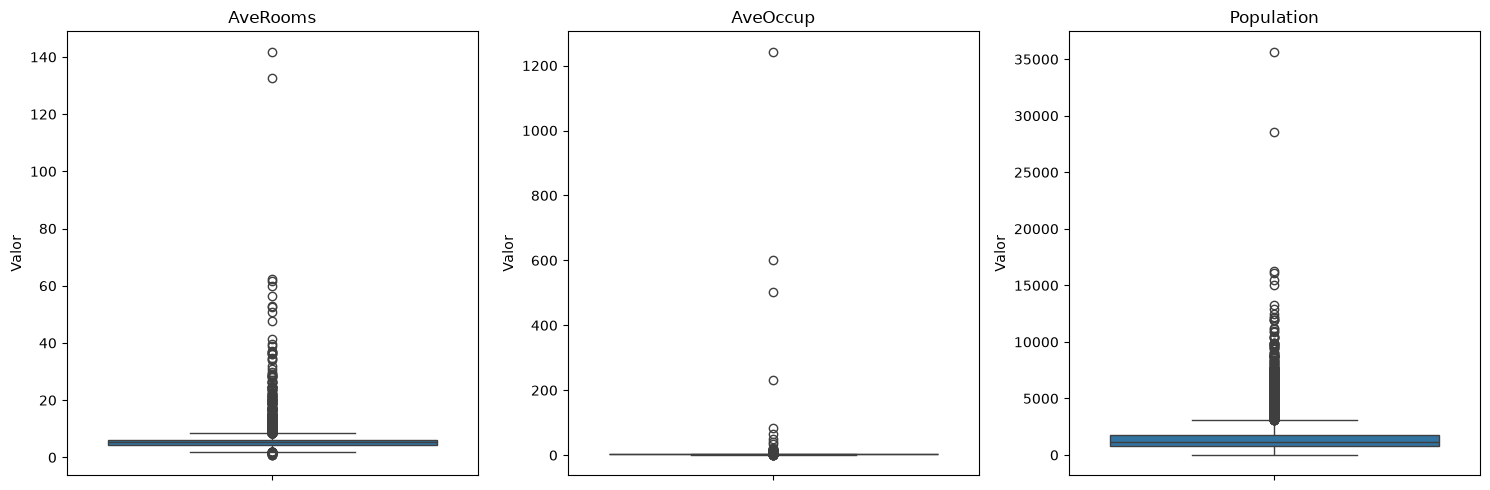

In [24]:
columnas_boxplot = ["AveRooms", "AveOccup", "Population"]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, columna in zip(axes, columnas_boxplot):
    sns.boxplot(y=california[columna], ax=ax)
    ax.set_title(columna)
    ax.set_ylabel("Valor")
plt.tight_layout()
plt.show()

### Ejercicio 12 · Z-score contra IQR

Para **cada columna** de `california`, cuenta cuántos outliers detecta el z-score ($|z| > 3$) y cuántos el IQR. Junta los resultados en un DataFrame con una fila por columna.

In [25]:
resultados_outliers = []
for columna in california.columns:
    serie = california[columna].dropna()
    z = np.abs((serie - serie.mean()) / serie.std()) > 3
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    limites = (q1 - 1.5 * iqr, q3 + 1.5 * iqr)
    fuera_iqr = (serie < limites[0]) | (serie > limites[1])
    resultados_outliers.append({
        "columna": columna,
        "outliers_zscore": int(z.sum()),
        "outliers_iqr": int(fuera_iqr.sum()),
    })

tabla_outliers = pd.DataFrame(resultados_outliers).set_index("columna")
tabla_outliers

,outliers_zscore,outliers_iqr
columna,,
MedInc,345,681
HouseAge,0,0
AveRooms,133,511
AveBedrms,145,1424
Population,342,1196
AveOccup,8,711
Latitude,0,0
Longitude,0,0
MedHouseVal,0,1071


✍️ **Pregunta:** en `AveOccup`, ¿por qué el z-score detecta tan pocos outliers y el IQR tantos? ¿Cuál de los dos números te parece más razonable?

En `AveOccup` hay una distribución muy asimétrica: la mayoría de los distritos está cerca de 2–3 personas por vivienda, pero unos pocos valores son enormes. Esos valores extremos aumentan mucho la media y la desviación estándar, por lo que el z-score solo marca 8 casos. El IQR usa los cuartiles y no queda tan afectado por la cola, por eso detecta 711. Para esta variable me parece más razonable el criterio de negocio combinado con el IQR, porque los valores extremos parecen errores o distritos con un denominador anómalo; el z-score oculta demasiados casos.

### Ejercicio 13 · Criterio de negocio

`AveOccup` es el número medio de personas que viven en cada vivienda del distrito.

a) Muestra los 5 distritos con mayor `AveOccup`.

b) Decide un **umbral razonable** por encima del cual el valor no tiene sentido, y elimina esos distritos. ¿Cuántos eliminaste?

In [26]:
print("Cinco distritos con mayor AveOccup:")
print(california.nlargest(5, "AveOccup")[["AveOccup", "Population", "AveRooms"]])

umbral_aveoccup = 20
california_limpia = california[california["AveOccup"] <= umbral_aveoccup].copy()
print("Umbral elegido:", umbral_aveoccup)
print("Distritos eliminados:", len(california) - len(california_limpia))

Cinco distritos con mayor AveOccup:
          AveOccup  Population  AveRooms
19006  1243.333333      7460.0  3.166667
3364    599.714286      4198.0  5.142857
16669   502.461538      6532.0  9.076923
13034   230.172414      6675.0  8.275862
9172     83.171429      8733.0  5.123810
Umbral elegido: 20
Distritos eliminados: 10


✍️ **Pregunta:** ¿qué umbral elegiste y por qué?

Elegí un umbral de 20 personas por vivienda. Es muy superior a una ocupación media normal y elimina los valores claramente imposibles sin eliminar automáticamente los distritos con una ocupación moderadamente alta. Con este criterio se eliminan 10 distritos.

### Ejercicio 14 · Winsorización

Winsoriza `AveRooms` en los percentiles 1 y 99, guardando el resultado en una columna nueva `AveRooms_wins`. Compara las estadísticas descriptivas de las dos columnas.

In [27]:
limite_inferior, limite_superior = california["AveRooms"].quantile([0.01, 0.99])
california["AveRooms_wins"] = california["AveRooms"].clip(
    lower=limite_inferior,
    upper=limite_superior,
)
print("Límites de winsorización:", limite_inferior, limite_superior)
california[["AveRooms", "AveRooms_wins"]].describe()

Límites de winsorización: 2.581133407821229 10.357033023735813


,AveRooms,AveRooms_wins
count,20640.000000,20640.000000
mean,5.429000,5.334186
std,2.474173,1.321643
min,0.846154,2.581133
25%,4.440716,4.440716
50%,5.229129,5.229129
75%,6.052381,6.052381
max,141.909091,10.357033


### Ejercicio 15 · Un caso raro

Muestra los 5 valores más frecuentes de `MedHouseVal`.

In [28]:
frecuencia_valores = california["MedHouseVal"].value_counts().head(5)
frecuencia_valores

MedHouseVal
5.00001    965
1.37500    122
1.62500    117
1.12500    103
1.87500     93
Name: count, dtype: int64

✍️ **Pregunta:** ¿qué crees que pasó con el valor más repetido? ¿Es un outlier? ¿Qué problema podría causarle a un modelo que intente predecir el valor de las viviendas?

El valor más repetido es `5.00001` y aparece 965 veces. Probablemente representa la censura superior del dataset: los valores de las viviendas se limitaron a un máximo cercano a 500.000 dólares, en vez de registrar el precio real de los distritos más caros. No es un outlier aislado, sino un valor acumulado en el límite superior. Puede perjudicar a un modelo porque muchos objetivos distintos quedan convertidos en el mismo valor, el modelo no puede aprender las diferencias entre las viviendas más caras y las predicciones quedan artificialmente truncadas.